# **Part2: Probability Theory Application**

In [ ]:
import pandas as pd
df = pd.read_csv("/content/drive/MyDrive/A1_Classification/cleaned_data.csv")
# Select a key feature (e.g., 'median_income')
key_feature = 'median_income'

## **1. Normal Distribution**

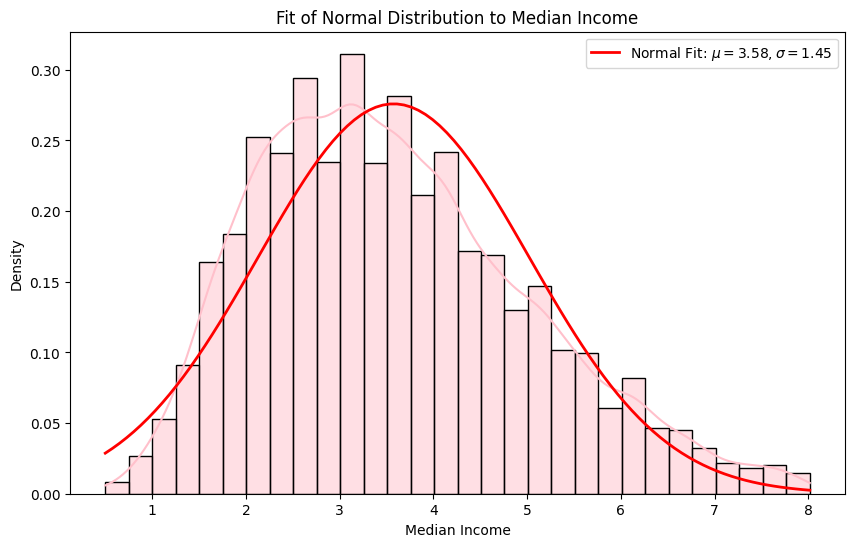

In [ ]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plot the histogram and fit the normal distribution
plt.figure(figsize=(10, 6))
sns.histplot(df[key_feature], bins=30, kde=True, color='pink', stat='density')
mu, std = stats.norm.fit(df[key_feature])
x = np.linspace(df[key_feature].min(), df[key_feature].max(), 100)
p = stats.norm.pdf(x, mu, std)

# Plot the fitted normal distribution
plt.plot(x, p, 'r', linewidth=2, label=f'Normal Fit: $\mu={mu:.2f}, \sigma={std:.2f}$')
plt.title('Fit of Normal Distribution to Median Income')
plt.xlabel('Median Income')
plt.ylabel('Density')
# Add a legend to distinguish between data and fitted distribution
plt.legend(loc='upper right', fontsize=10)

plt.show()


The red curve represents the fitted normal distribution with a mean (μ) of 3.58 and a standard deviation (σ ) of 1.45. The pink bars show the histogram of the actual median_income values in the dataset with the overlaid pink curve.


While the normal distribution fits the central part of the data well, the tails of the distribution are not perfectly captured by the normal fit.
- Left tail: The left side (lower income values) shows a steeper drop compared to the normal distribution curve, indicating that there are fewer households with very low incomes than the normal distribution would predict.
- Right tail: The right side of the distribution (higher incomes) falls fater than the fitted curve, suggesting that there are more higher-income households than what a normal distribution would expect at the extreme right.


Although the tails on both sides are slightly biased, in general, the fitted normal distribution can effectively describe most of the features of the data, especially the data close to the mean.

## **2. Kolmogorov-Smirnov test**

In [ ]:
# K-S test
ks_statistic, p_value = stats.kstest(df[key_feature], 'norm', args=(mu, std))

# print K-S result
print(f'K-S Statistic: {ks_statistic}')
print(f'P-Value: {p_value}')

# hypothesis test using p-value
alpha = 0.05  # significance level
if p_value < alpha:
    print("Rejection of the null hypothesis: data do not follow a normal distribution")
else:
    print("Null hypothesis cannot be rejected: data follow a normal distribution")

K-S Statistic: 0.05515386237373526
P-Value: 4.099646168335164e-45
Rejection of the null hypothesis: data do not follow a normal distribution


## **3. Calculate the conditional probability of median house value given certain features**

**Use quartiles (e.g., 25%, 50%, 75%, etc.) to convert the median house value into discrete classes("Low",
"Medium", "High")**

In [ ]:
# Calculation of quartiles
q25 = df['median_house_value'].quantile(0.25)
q50 = df['median_house_value'].quantile(0.5)
q75 = df['median_house_value'].quantile(0.75)

# Setting interval
bins = [-float('inf'), q25, q75, float('inf')]
labels = ['Low', 'Medium', 'High']

# Discret median_house_value
df['house_value_category'] = pd.cut(df['median_house_value'], bins=bins, labels=labels)

print(df[['median_house_value', 'house_value_category']].head())

   median_house_value house_value_category
0            352100.0                 High
1            341300.0                 High
2            342200.0                 High
3            269700.0                 High
4            299200.0                 High


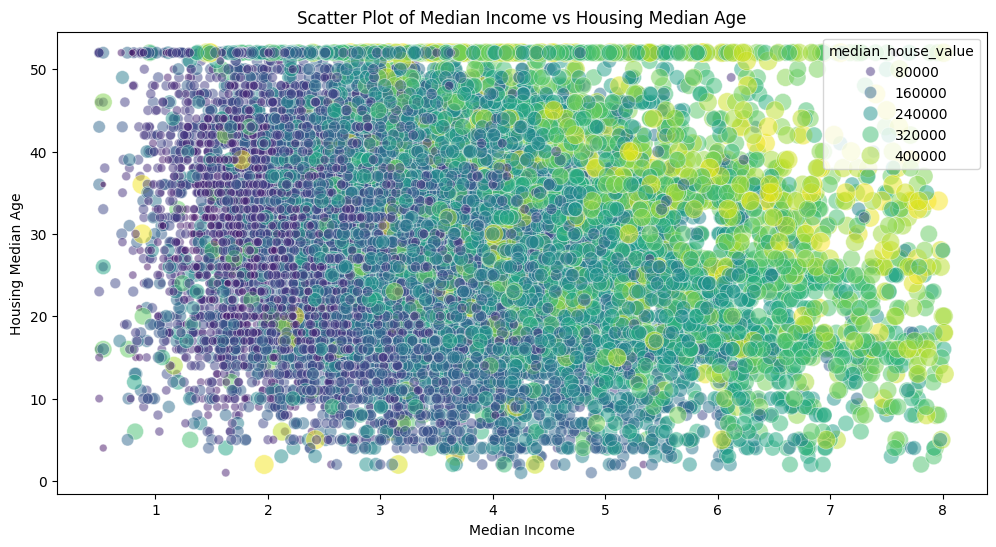

In [ ]:
# Calculate the conditional probability of median house value given certain features
# use groupby
conditional_prob = df.groupby(['median_income', 'housing_median_age'])['median_house_value'].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.scatterplot(data=df, x='median_income', y='housing_median_age',
                size='median_house_value', sizes=(20, 200), alpha=0.5,
                hue='median_house_value', palette='viridis')
plt.title('Scatter Plot of Median Income vs Housing Median Age')
plt.xlabel('Median Income')
plt.ylabel('Housing Median Age')
plt.show()

The scatter plot generated from this analysis reveals that areas with higher median_income tend to have higher house prices, confirming that median_income is a key feature for predicting house prices. On the other hand, housing_median_age appears to have a more subtle effect on house prices, showing a weaker relationship.

## **4.Computer the expected value and variance**

In [ ]:
expected_value = df['median_income'].mean()
variance = df['median_income'].var()

print(f'Expected Value (Mean) of Median Income: {expected_value:.2f}')
print(f'Variance of Median Income: {variance:.2f}')

Expected Value (Mean) of Median Income: 3.58
Variance of Median Income: 2.09


The variance is 2.09, which measures the spread or dispersion of the data. A higher variance indicates more variability in income levels across different households in the dataset, while a lower variance would suggest incomes are closer to the mean. In this case, the variance shows moderate variability in the median income values, meaning that while most values are close to the mean, there are some incomes further away from the average.